# 4.3.5. ML4 - Federated Learning

Notebook có sẵn kết quả của Centralized, FedAvg và FedProx, cùng ba hình:
so sánh chỉ số test, đường huấn luyện validation và phân bố client.

Trong VS Code chọn **Select Kernel**, rồi **Run All** để đọc lại kết quả.
`RUN_TRAINING = False` mặc định; đổi thành `True` để huấn luyện lại.
Kết quả lưu ở `ml4_results`. Đây là một lần chạy ML4, không phải trung bình nhiều seed.


## Môi trường

Cài extension Python và Jupyter của Microsoft. Nếu thiếu thư viện, bỏ dấu `#`
ở ô cài đặt dưới rồi chạy. Mọi bước chạy script dùng đúng Python của kernel đang chọn.


In [1]:
# %pip install -r requirements_ml4.txt


In [2]:
from pathlib import Path
import sys
import json
import subprocess
import pandas as pd
from IPython.display import Image, Markdown

BASE = Path.cwd()
if not (BASE / 'run_ml4_federated.py').exists() and (BASE / 'outputs').exists():
    BASE = BASE / 'outputs'
RESULTS = BASE / 'ml4_results'
print('Thư mục kết quả:', RESULTS)
print('Python kernel:', sys.executable)


Thư mục kết quả: C:\Users\84969\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\outputs\ml4_results
Python kernel: C:\Program Files\Python313\python.exe


In [3]:
RUN_TRAINING = False
ROUNDS = 20
LOCAL_EPOCHS = 3
LEARNING_RATE = 0.05
FEDPROX_MU = 0.1

if RUN_TRAINING:
    required = ['run_ml4_federated.py', 'ml4_train.csv.gz', 'ml4_val.csv.gz',
                'ml4_test.csv.gz', 'client_partition_metadata.csv']
    missing = [name for name in required if not (BASE / name).exists()]
    assert not missing, f'Thiếu file: {missing}'
    command = [sys.executable, '-u', str(BASE / 'run_ml4_federated.py'),
               '--data-dir', str(BASE), '--output-dir', str(RESULTS),
               '--rounds', str(ROUNDS), '--local-epochs', str(LOCAL_EPOCHS),
               '--lr', str(LEARNING_RATE), '--fedprox-mu', str(FEDPROX_MU)]
    process = subprocess.Popen(command, cwd=BASE, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8')
    for line in process.stdout:
        print(line, end='')
    if process.wait() != 0:
        raise RuntimeError('Huấn luyện bị lỗi. Đọc dòng lỗi phía trên.')
else:
    print('Đang đọc kết quả có sẵn, chưa chạy lại huấn luyện.')
assert (RESULTS / 'ml4_results_summary.csv').exists(), 'Chưa có kết quả. Đổi RUN_TRAINING=True.'
summary = json.loads((RESULTS / 'ml4_experiment_summary.json').read_text(encoding='utf-8'))
results = pd.read_csv(RESULTS / 'ml4_results_summary.csv')
history = pd.read_csv(RESULTS / 'ml4_training_history.csv')
report = (RESULTS / 'ML4_Federated_Learning_Report.md').read_text(encoding='utf-8')

def report_section(number):
    body = report.split(f'## 4.3.5.{number}.', 1)[1].split('## 4.3.5.', 1)[0]
    return ''.join(body.splitlines(keepends=True)[1:])


Đang đọc kết quả có sẵn, chưa chạy lại huấn luyện.


## 4.3.5.1. Thiết lập client

Mỗi session là một dòng dự đoán purchase. Mọi session của cùng `visitorid` được
ánh xạ vào cùng một client. Hình bên trái dùng số phiên TRAIN; hình bên phải dùng
purchase rate trên tổng ba split, đúng theo metadata đã chuẩn bị.


,split,sessions,purchase_rate,clients
0,train,1408588,0.007601,50
1,val,176074,0.007855,50
2,test,176074,0.007207,50


,client_id,n_train_sessions,n_val_sessions,n_test_sessions,purchase_rate
0,client_0000,29065,3592,3526,0.007517
1,client_0001,28604,3484,3502,0.007390
2,client_0002,28295,3420,3480,0.007331
3,client_0003,27796,3442,3633,0.006883
4,client_0004,28042,3461,3514,0.007425
5,client_0005,28248,3603,3644,0.007832
6,client_0006,28101,3528,3701,0.007189
7,client_0007,27958,3464,3422,0.008065
8,client_0008,28305,3486,3510,0.006714
9,client_0009,27754,3370,3488,0.007743


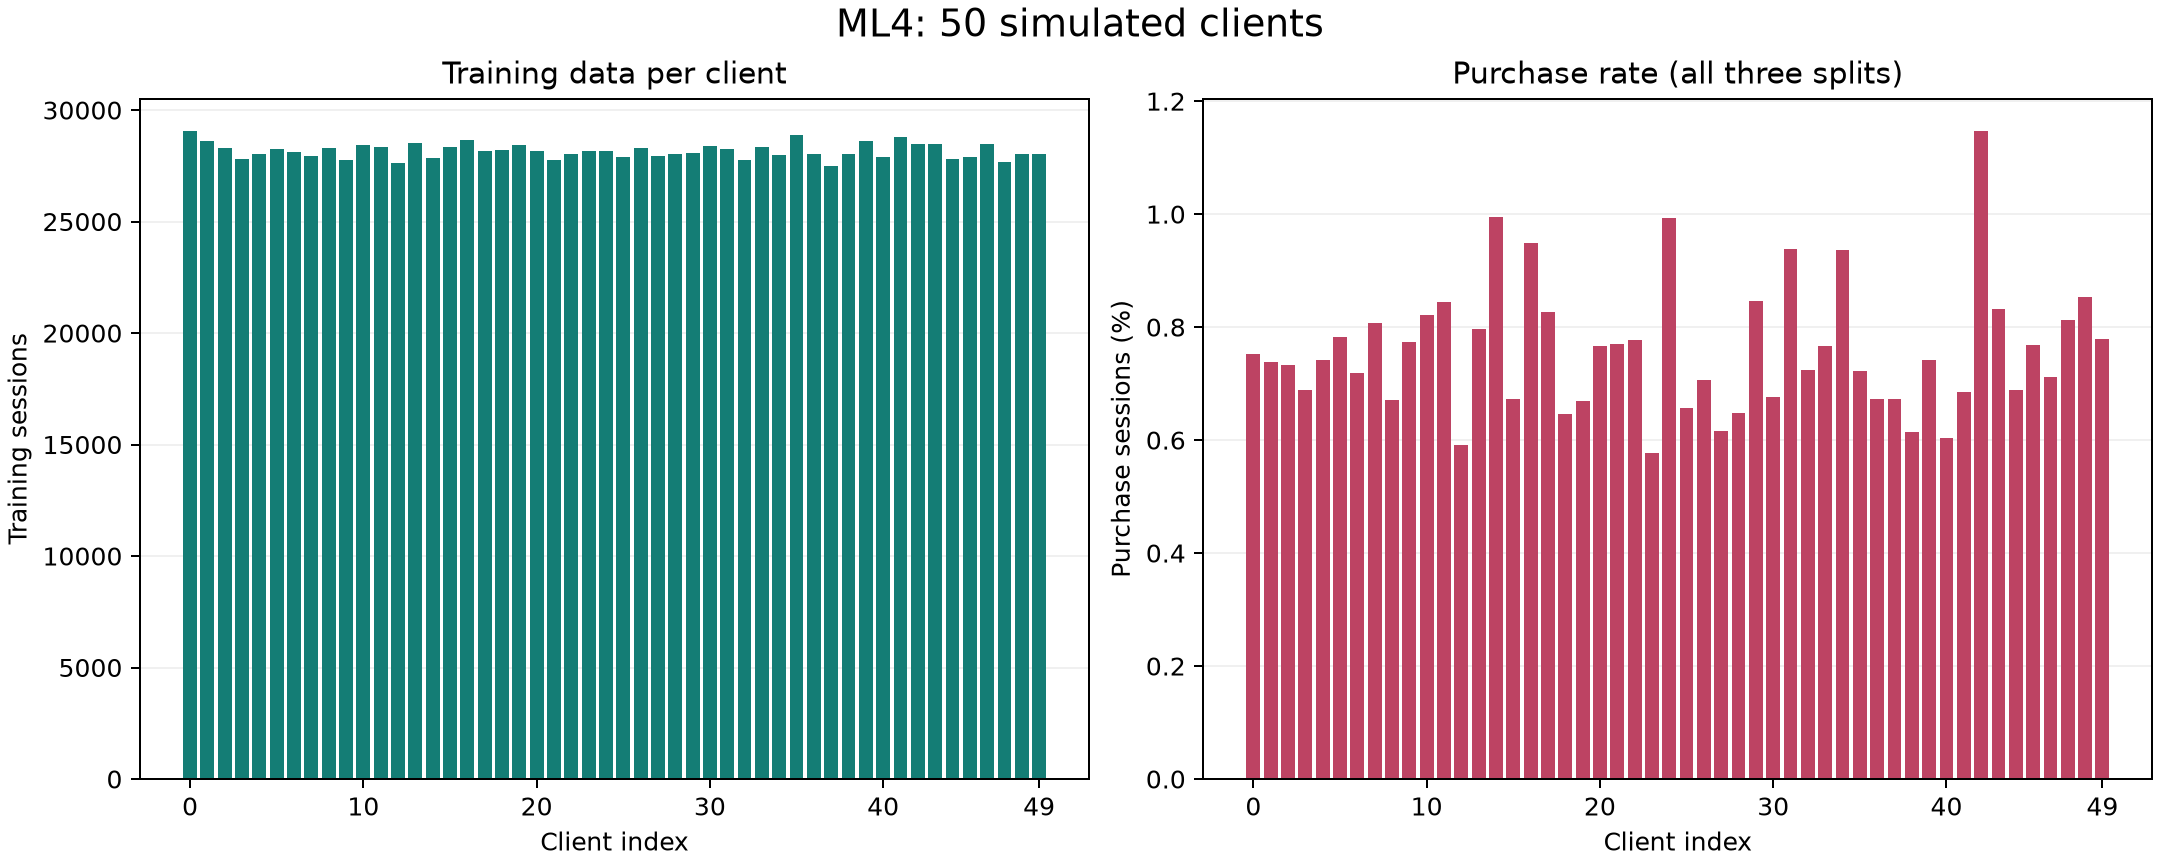

In [4]:
client_meta = pd.read_csv(BASE / 'client_partition_metadata.csv')
split_rows = []
for split in ['train', 'val', 'test']:
    split_rows.append({'split': split, 'sessions': summary[f'{split}_rows'],
                       'purchase_rate': summary[f'{split}_positive_rate'],
                       'clients': int((client_meta[f'n_{split}_sessions'] > 0).sum())})
display(pd.DataFrame(split_rows))
display(client_meta[['client_id', 'n_train_sessions', 'n_val_sessions',
                     'n_test_sessions', 'purchase_rate']].head(10))
display(Image(filename=str(RESULTS / 'ml4_client_distribution.png')))


## 4.3.5.2. Centralized Training

Phần dưới lấy trực tiếp nội dung báo cáo: cấu hình, bảng validation/test và nhận xét
về khả năng nhận diện phiên mua hàng của baseline.


In [5]:
metrics = ['roc_auc', 'pr_auc', 'balanced_accuracy', 'precision', 'recall', 'f1']
test_cols = ['model'] + [f'test_{metric}' for metric in metrics]
display(Markdown(report_section(2)))



Centralized Training dùng toàn bộ tập train để huấn luyện một mô hình Logistic Regression. Đây là baseline tập trung, dùng để so sánh với FedAvg và FedProx. Mô hình chỉ sử dụng các đặc trưng quan sát được trước nhãn mua hàng như số sự kiện quan sát được, số lượt xem, số lượt thêm giỏ hàng, số sản phẩm khác nhau, thời lượng quan sát và tỷ lệ view-to-cart.

Mô hình được huấn luyện trên 1,408,588 phiên bằng
`SGDClassifier(loss="log_loss")`, với class weight `balanced`, regularization L2
(α = 0.00001), `max_iter = 20`, `tol = 0.0001` và `random_state = 42`.
`StandardScaler` được fit trên train rồi dùng chung cho validation/test.
Ngưỡng phân loại trong lần chạy này là 0.5.

Kết quả của baseline trên hai tập đánh giá:

| Chỉ số | Validation | Test |
| --- | ---: | ---: |
| ROC-AUC | 0.9332 | 0.9293 |
| PR-AUC (average precision) | 0.1361 | 0.1370 |
| Balanced Accuracy | 0.9133 | 0.9128 |
| Precision | 0.0946 | 0.0898 |
| Recall | 0.8944 | 0.8913 |
| F1 | 0.1711 | 0.1631 |
| Accuracy | 0.9319 | 0.9341 |

Trên test, ROC-AUC đạt 0.9293 và PR-AUC đạt
0.1370. Recall = 0.8913 cho biết
mô hình nhận diện khoảng 89.13% phiên mua hàng,
trong khi Precision = 0.0898 cho biết chỉ khoảng
8.98% phiên được dự đoán mua thực sự có mua.
Baseline phát hiện nhiều phiên positive nhưng còn nhiều dự đoán dương tính giả,
thể hiện qua F1 = 0.1631.

Mô hình gán nhãn mua cho 7.15% phiên
test, trong khi tỷ lệ mua thực tế chỉ 0.72%.
Accuracy = 0.9341 vì vậy cần đọc cùng Balanced Accuracy
= 0.9128, PR-AUC và F1. ROC-AUC validation =
0.9332 so với test = 0.9293;
PR-AUC validation = 0.1361 so với test =
0.1370. Các chỉ số này khá gần nhau trong lần chạy đã lưu.



## 4.3.5.3. FedAvg

Phần dưới trình bày kết quả sau round cuối, tiến trình validation đã ghi và so sánh
với baseline centralized trong cùng lần chạy.


In [6]:
display(pd.DataFrame([summary['config']]))
display(Markdown(report_section(3)))


,rounds,local_epochs,lr,fedprox_mu,threshold
0,20,3,0.05,0.1,0.5



FedAvg được mô phỏng bằng cách huấn luyện mô hình cục bộ trên từng client, sau đó server tổng hợp tham số theo trung bình có trọng số dựa trên số mẫu của mỗi client. Số vòng huấn luyện là 20, learning rate là 0.05, và mỗi client chạy 3 local epoch trong một vòng.

Tất cả 50 client tham gia mỗi round. Trong script, mỗi local
epoch là một bước gradient dùng toàn bộ dữ liệu cục bộ. Mô hình dùng cùng bảy đặc
trưng/scaler với baseline, với trọng số purchase 130.5700
so với trọng số 1 của lớp không mua.

Kết quả của FedAvg sau round cuối:

| Chỉ số | Validation | Test |
| --- | ---: | ---: |
| ROC-AUC | 0.9475 | 0.9427 |
| PR-AUC (average precision) | 0.2444 | 0.2449 |
| Balanced Accuracy | 0.9306 | 0.9270 |
| Precision | 0.2045 | 0.1964 |
| Recall | 0.8886 | 0.8802 |
| F1 | 0.3324 | 0.3211 |
| Accuracy | 0.9720 | 0.9732 |

Lịch sử validation cho thấy từ round 1 đến round 20, PR-AUC thay đổi từ 0.2410 sang 0.2444, F1 từ 0.1229 sang 0.3324 và Precision từ 0.0659 sang 0.2045. Recall thay đổi từ 0.9111 sang 0.8886. Các giá trị này được lấy từ `ml4_training_history.csv`, không phải lịch sử test.

Trên test, FedAvg đạt PR-AUC = 0.2449, F1 =
0.3211 và Precision = 0.1964. Hiệu số
**FedAvg − Centralized** là +0.1078
cho PR-AUC và +0.1580 cho F1 trên thang 0 đến 1.
Precision chuyển từ 0.0898 ở centralized sang
0.1964 ở FedAvg, còn Recall từ 0.8913
sang 0.8802. Kết quả thể hiện sự đánh đổi giữa độ chính xác của
các dự đoán mua và khả năng bao phủ các phiên có mua hàng.

Phương án huấn luyện theo client đạt chất lượng dự đoán tốt trong mô phỏng này.
Tuy nhiên, centralized và FedAvg dùng lịch tối ưu khác nhau; chênh lệch quan sát
được chưa tách riêng ảnh hưởng của thuật toán FL khỏi cấu hình tối ưu.



## 4.3.5.4. FedProx

Phần dưới trình bày kết quả FedProx và chênh lệch với FedAvg ở sáu chữ số thập phân.
Biểu đồ dùng nét liền cho FedAvg, nét đứt cho FedProx; hai đường rất gần nhau.



FedProx sử dụng cùng thiết lập với FedAvg nhưng bổ sung proximal term để hạn chế mô hình cục bộ lệch quá xa mô hình global. Hệ số proximal trong lần chạy này là `0.1`.

Thiết lập giữ nguyên 50 client, 20 round,
3 local epoch và learning rate 0.05 như FedAvg.
Trong bản ML4 này, proximal term được áp dụng cho vector weight, không áp dụng
cho bias. Mọi client đều tham gia và server tổng hợp theo số phiên train.

Kết quả của FedProx sau round cuối:

| Chỉ số | Validation | Test |
| --- | ---: | ---: |
| ROC-AUC | 0.9475 | 0.9427 |
| PR-AUC (average precision) | 0.2444 | 0.2449 |
| Balanced Accuracy | 0.9306 | 0.9270 |
| Precision | 0.2045 | 0.1963 |
| Recall | 0.8886 | 0.8802 |
| F1 | 0.3324 | 0.3211 |
| Accuracy | 0.9720 | 0.9732 |

Lịch sử validation cho thấy từ round 1 đến round 20, PR-AUC thay đổi từ 0.2410 sang 0.2444, F1 từ 0.1230 sang 0.3324 và Precision từ 0.0659 sang 0.2045. Recall thay đổi từ 0.9111 sang 0.8886. Các giá trị này được lấy từ `ml4_training_history.csv`, không phải lịch sử test.

Trên test, FedProx đạt ROC-AUC = 0.9427, PR-AUC =
0.2449, F1 = 0.3211 và Recall =
0.8802. Các giá trị này rất gần FedAvg. Để tránh việc làm tròn
bốn chữ số che mất chênh lệch, hiệu số **FedProx − FedAvg** trên test được ghi thêm
ở độ chính xác sáu chữ số: PR-AUC = -0.000014,
F1 = -0.000046 và ROC-AUC =
-0.000001.

Với μ = 0.1 và cách chia client hiện tại, chưa quan sát được lợi
thế chất lượng dự đoán rõ của FedProx so với FedAvg. Các chênh lệch rất nhỏ trong
một lần chạy chưa đủ để kết luận phương pháp nào vượt trội về thống kê. Mức độ
không đồng nhất giữa client và lựa chọn μ có thể ảnh hưởng kết quả, nhưng lần thử
này chưa quét nhiều μ hay thay đổi mức non-IID để xác định nguyên nhân.



,round,algorithm,val_accuracy,val_balanced_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_pr_auc,val_positive_rate_pred
15,16,FedAvg,0.96909,0.92990,0.18875,0.89009,0.31145,0.94747,0.24391,0.03704
16,17,FedAvg,0.96980,0.92991,0.19237,0.88937,0.31632,0.94748,0.24403,0.03631
17,18,FedAvg,0.97063,0.93032,0.19683,0.88937,0.32233,0.94749,0.24415,0.03549
18,19,FedAvg,0.97136,0.93069,0.20101,0.88937,0.32791,0.94750,0.24428,0.03475
19,20,FedAvg,0.97197,0.93064,0.20446,0.88865,0.33243,0.94751,0.24444,0.03414
35,16,FedProx,0.96909,0.92990,0.18875,0.89009,0.31145,0.94747,0.24390,0.03704
36,17,FedProx,0.96980,0.92990,0.19234,0.88937,0.31628,0.94748,0.24403,0.03632
37,18,FedProx,0.97062,0.93032,0.19680,0.88937,0.32228,0.94749,0.24414,0.03550
38,19,FedProx,0.97136,0.93069,0.20098,0.88937,0.32787,0.94750,0.24426,0.03476
39,20,FedProx,0.97197,0.93064,0.20446,0.88865,0.33243,0.94751,0.24442,0.03414


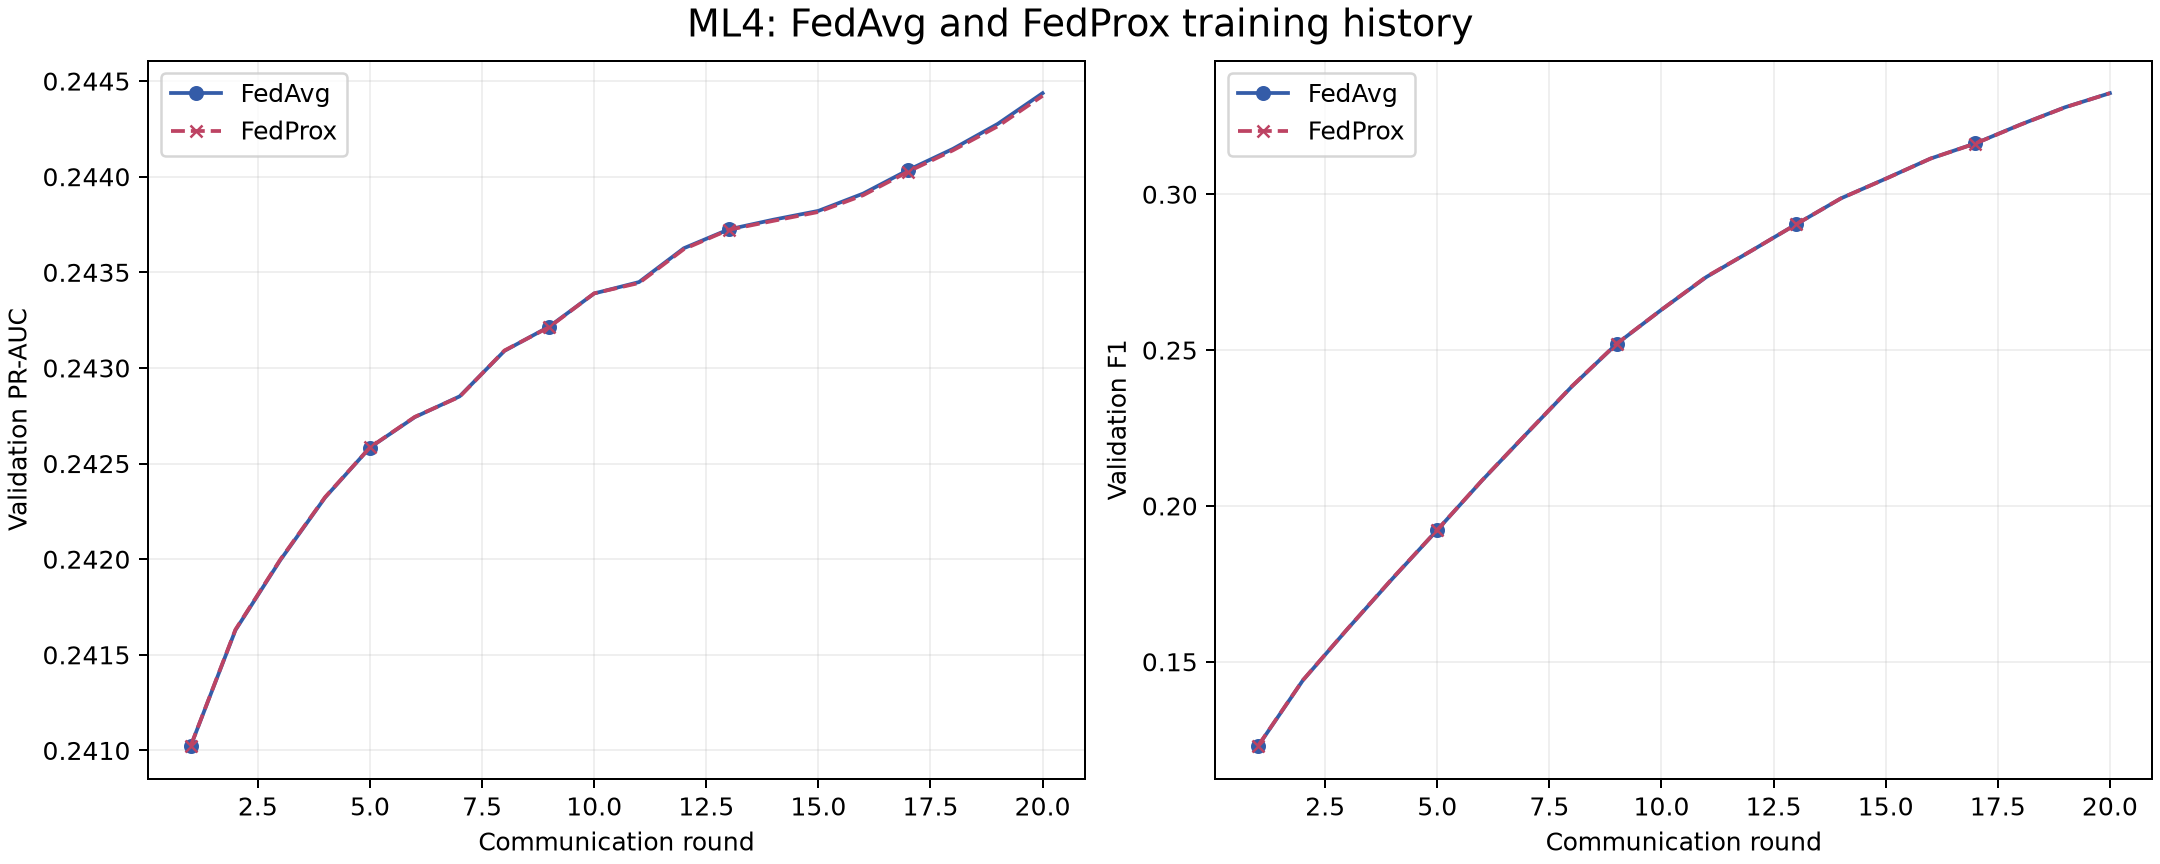

In [7]:
display(Markdown(report_section(4)))
display(history.groupby('algorithm', sort=False).tail(5).round(5))
display(Image(filename=str(RESULTS / 'ml4_training_curves.png')))


## 4.3.5.5. So sánh kết quả

PR-AUC ở đây là average precision. Purchase hiếm nên ưu tiên PR-AUC, F1,
ROC-AUC và balanced accuracy hơn accuracy tổng thể. Hình không có error bar
qua nhiều seed vì ML4 hiện chỉ có một lần chạy.


,model,test_roc_auc,test_pr_auc,test_balanced_accuracy,test_precision,test_recall,test_f1
0,Centralized Logistic Regression,0.92932,0.13704,0.91283,0.08979,0.89125,0.16314
1,FedAvg,0.94268,0.24487,0.92704,0.19638,0.88022,0.32112
2,FedProx,0.94268,0.24485,0.92703,0.19634,0.88022,0.32107


,model,val_pr_auc,test_pr_auc,val_f1,test_f1
0,Centralized Logistic Regression,0.13613,0.13704,0.17112,0.16314
1,FedAvg,0.24444,0.24487,0.33243,0.32112
2,FedProx,0.24442,0.24485,0.33243,0.32107


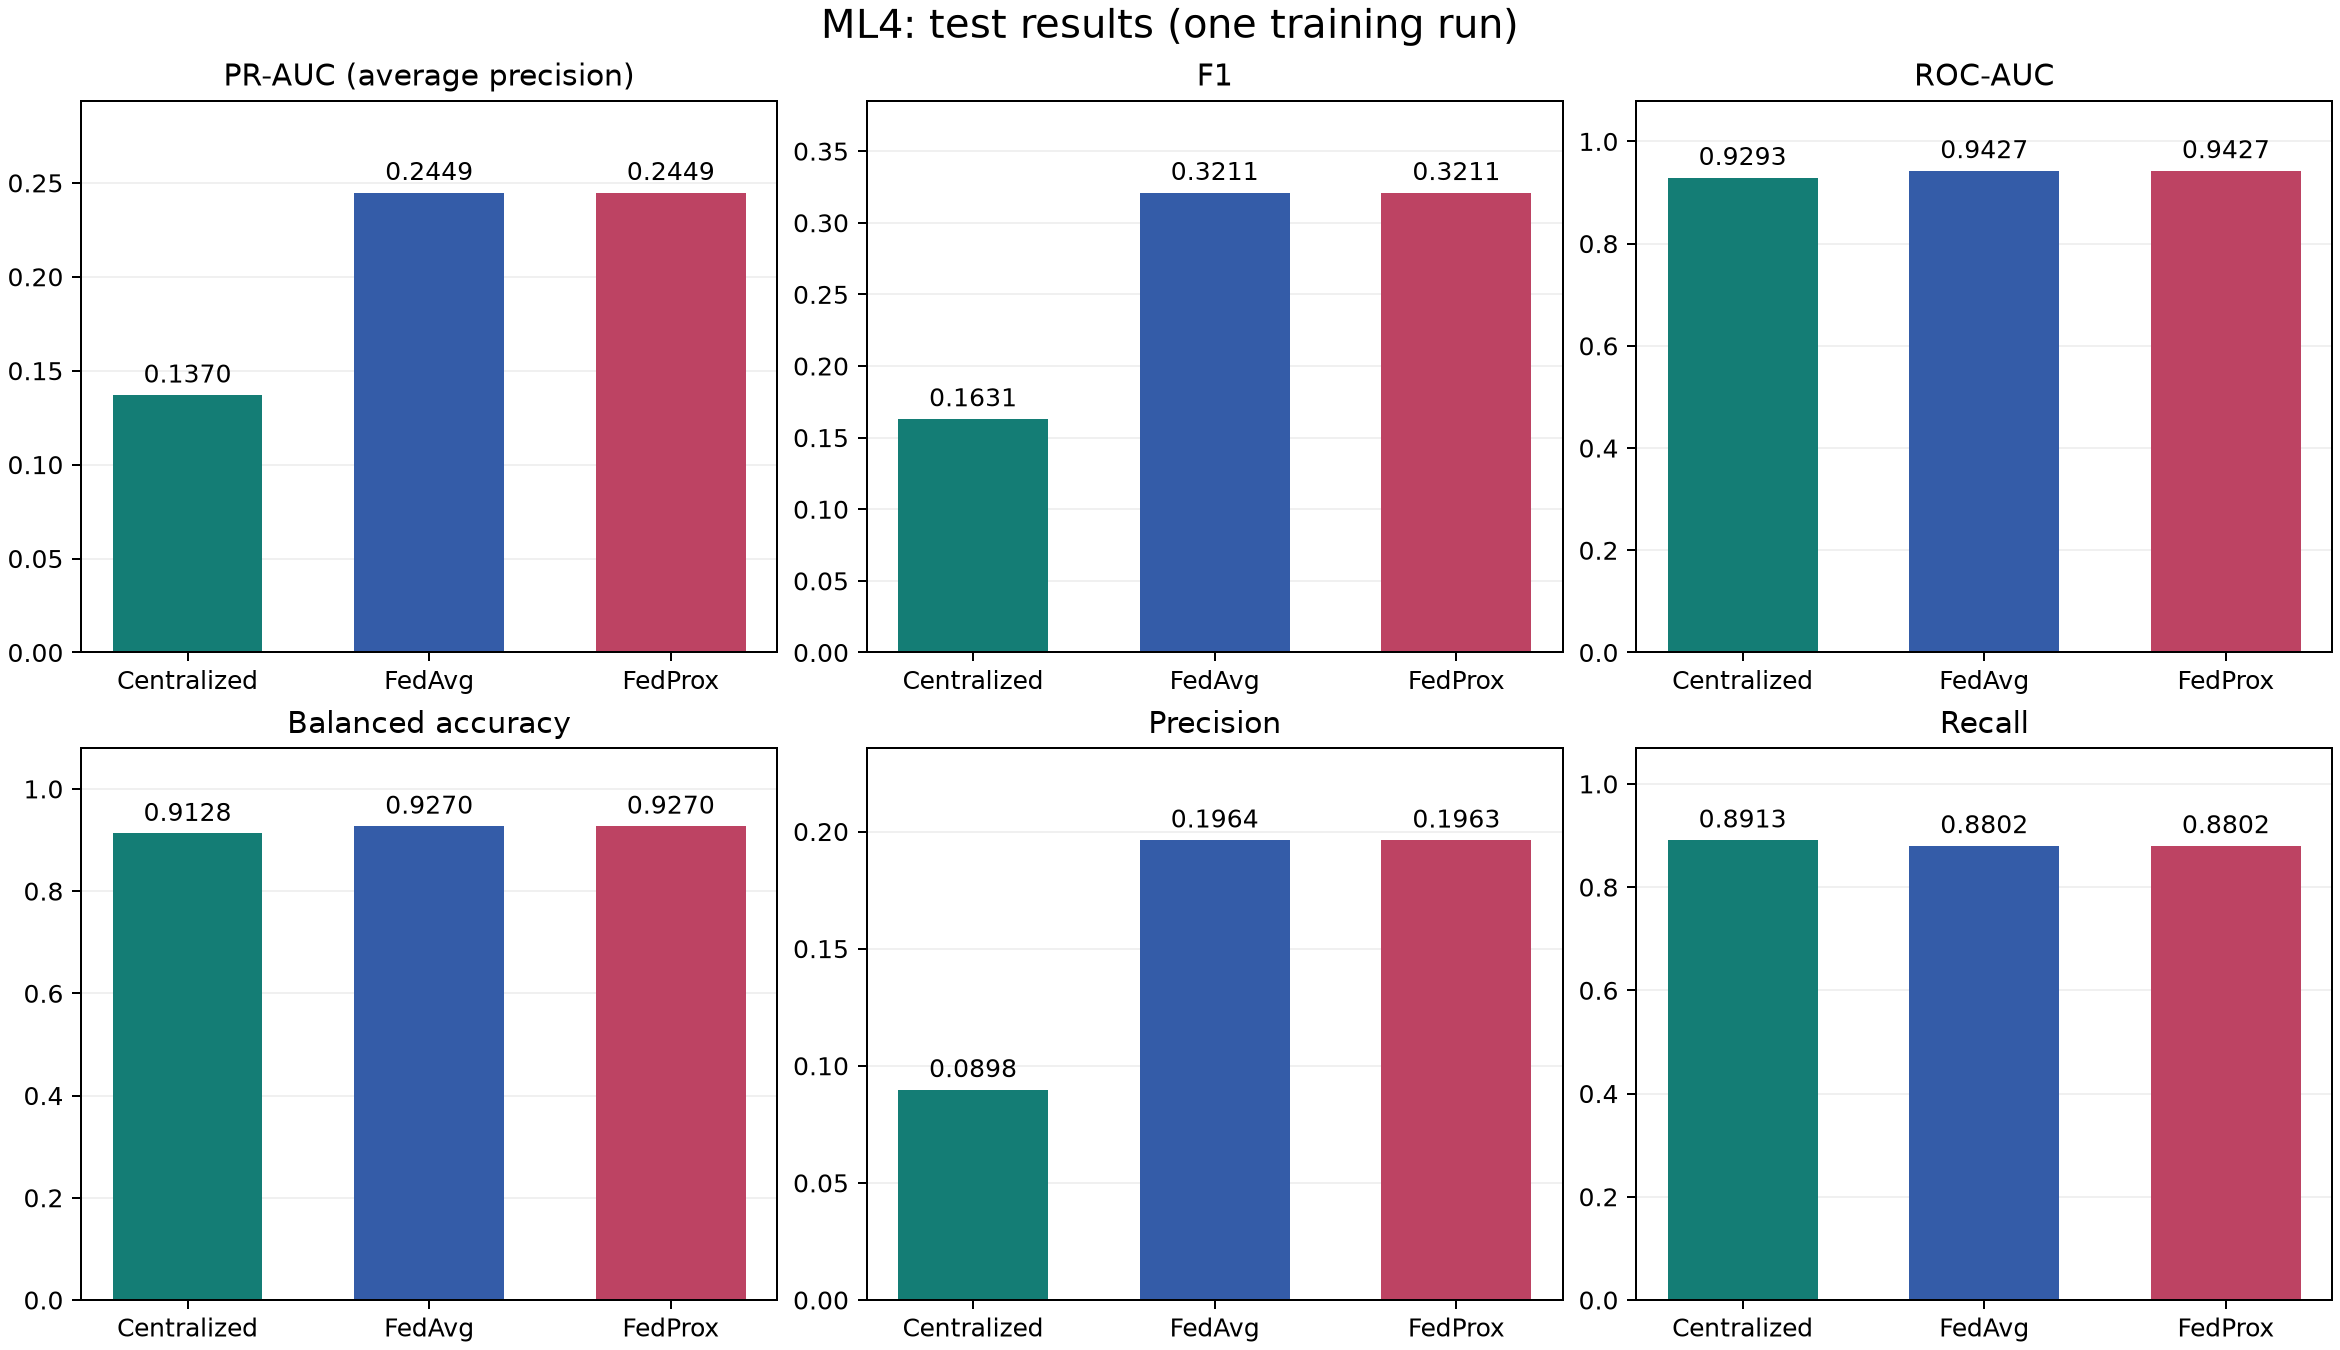

In [8]:
display(results[test_cols].round(5))
display(results[['model', 'val_pr_auc', 'test_pr_auc', 'val_f1', 'test_f1']].round(5))
display(Image(filename=str(RESULTS / 'ml4_model_comparison.png')))


## 4.3.5.6. Trả lời câu hỏi RQ4

Phần bên dưới lấy từ báo cáo lưu cùng kết quả. ML4 là mô phỏng trên một máy;
không phải hệ thống client phân tán đã triển khai. FL chưa tự tạo bảo đảm DP.


In [9]:
report = (RESULTS / 'ML4_Federated_Learning_Report.md').read_text(encoding='utf-8')
display(Markdown(report.split('## 4.3.5.6. Trả lời RQ4', 1)[1]))
print('File bảng, hình và báo cáo đều ở:', RESULTS)




Kết quả cho thấy Federated Learning có thể huấn luyện mô hình dự đoán mua hàng mà không cần gom toàn bộ dữ liệu raw event về một nơi trong quá trình mô phỏng client. FedAvg và FedProx sử dụng cùng dữ liệu đã chia theo client, chỉ tổng hợp tham số mô hình ở phía server. So với Centralized Training, hiệu quả của FL phụ thuộc vào mức độ không đồng nhất giữa client, số vòng truyền thông, learning rate và số mẫu trên từng client.

Trong thiết lập này, FedAvg và FedProx cho kết quả gần như tương đương. Chưa quan
sát được lợi thế rõ của FedProx với bộ đặc trưng session, μ và cách chia client hiện
tại. Lần chạy này chưa quét μ hoặc thay đổi mức non-IID, nên chưa thể xác định
nguyên nhân của sự tương đồng. Cả hai phương pháp FL đạt kết quả cạnh tranh với
baseline tập trung trên ROC-AUC, PR-AUC, Balanced Accuracy và F1; việc diễn giải
chênh lệch vẫn cần xét đến lịch tối ưu khác nhau của các mô hình.

Kết luận cho RQ4: Federated Learning là khả thi trong bối cảnh dữ liệu thương mại điện tử đã chia theo khách hàng, vì mô hình vẫn có thể được huấn luyện thông qua tổng hợp tham số mà không cần tập trung raw data của từng client. Tuy nhiên, chất lượng mô hình phụ thuộc vào cách chia client, mức độ non-IID, số vòng huấn luyện, learning rate và số local epoch.


File bảng, hình và báo cáo đều ở: C:\Users\84969\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\outputs\ml4_results


## Chạy lại chỉ phần biểu đồ

Trong Terminal ở thư mục notebook, chạy:

```powershell
python run_ml4_federated.py --data-dir . --output-dir ml4_results --plots-only
```

Không cần giải nén ba file `.csv.gz`. Đọc `ML4_README.md` để xem hướng dẫn đầy đủ.
